# Experiment A2 · Does historical RankMe agree with local reconstruction?

**Complete** · 414/414 seed–state pairs · 2026-11-25T12:37:49+01:00

The notebook refreshes after the first decision, every six decisions, and at completion. Reopen it for the latest snapshot.

## Protocol

Six candidate rates (Skip, 0.1×, 0.25×, 0.5×, 1× and 2×) use a base LR of 0.003. Every non-skip branch takes one AdamW step on the same origin frame and training mask. Branches start with identical weights and optimizer moments. Inference uses matched evaluation masks on the next 16 frames from that clip. Horizons 1, 4, 8 and 16 are nested prefixes. Bank RankMe uses uncentered encoder embeddings on nested sets of 64, 128, 256 and 512 historical images.

Each seed draws one image per capture across eight periods of its observed 8,000-image history. Selection and audit banks contain 512 distinct captures each. All bank captures are disjoint from probe and decision/calibration clips. The independent local audit always uses frames 17–32. Query and audit labels never enter the selector.

**Calibration.** For each seed, five separate clips × six origins × five non-skip actions give 150 paired changes at its starting checkpoint. Divide each horizon’s loss decrease and each bank size’s rank increase by its own RMS action effect. Scales are frozen for all evaluation decisions.

**Selection.** A branch is Pareto dominated if another is at least as good on both metrics and strictly better on one. For a single commitment, take the frontier action with the smallest maximum normalized shortfall from the per-state ideal on each axis. Exact ties on the frontier prefer the lower LR. Weighted alternatives sweep the RankMe coefficient from 0 to 1. Constrained alternatives minimize loss or maximize rank, allowing a decline of up to 0.1 calibration RMS in the guarded component.

**Commit and audit.** The 16-frame/128-image Pareto choice carries both model and AdamW state to the next clip. Each seed starts six separate 23-clip walks from its calibrated MAE checkpoint, one for each origin offset (0, 6, 12, 18, 24, 31). Within each walk every clip occurs once. The six offsets revisit the same 23 captures across independent trajectories. Alternative policies are scored on the common visited states. All grid choices are locked before audit-window, audit-bank and downstream scoring.

## Do the objectives compete?

At 16 frames and 128 bank images, **8.2%** of measured states offer an update that strictly improves both metrics over Skip. **79.5%** have multiple nondominated candidates. In **80.2%** at least one pair of actions reverses order between reconstruction and RankMe. These frequencies can overlap.

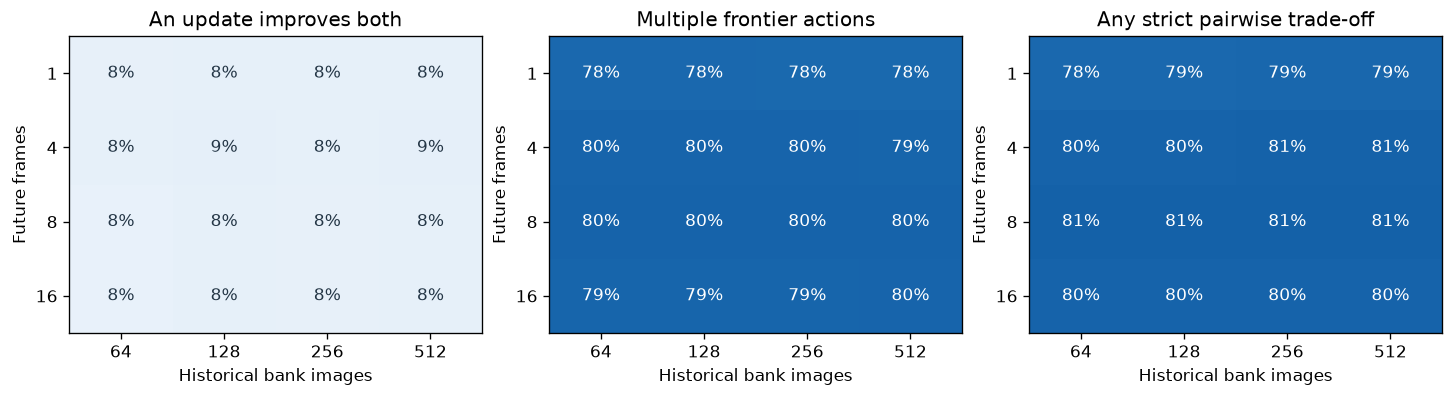

In [ ]:
# Embedded plot from the completed decision states.

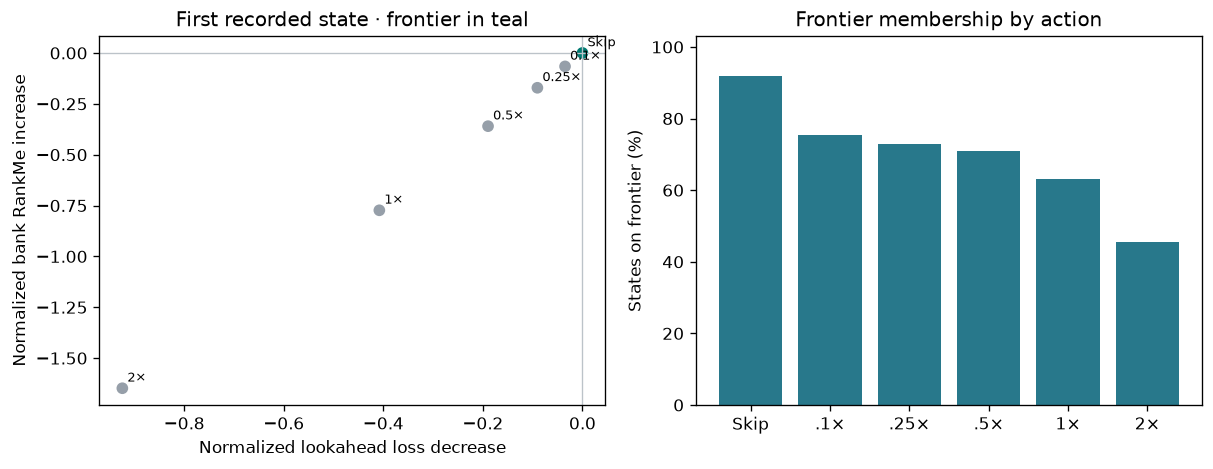

In [ ]:
# Embedded plot from the completed decision states.

## How do the choices transfer?

All selectors below see the same state, 16 future frames and 128 selection-bank images. The audit uses frames 17–32 and separate historical captures. Q is the equally weighted mean of five refitted probes’ balanced accuracies. Forgetting is the pre-update minus post-update accuracy of the checkpoint’s frozen heads. Oracle regret is best available Q minus chosen Q, in percentage points. A tie for best Q counts as a hit.

| Selector | Train | Audit loss gain | Audit rank gain | ΔQ vs Skip (pp) | Regret (pp) | Best Q | Forgetting (pp) |
|---|---:|---:|---:|---:|---:|---:|---:|
| Pareto compromise | 76.8% | +0.030246 | -0.16597 | -0.002 | 0.244 | 17.1% | +0.638 |
| Loss with rank guard | 76.6% | +0.015654 | -0.03034 | -0.003 | 0.245 | 11.8% | +0.123 |
| Rank with loss guard | 8.7% | +0.005394 | +0.00749 | +0.003 | 0.239 | 17.4% | +0.011 |
| Rank weight 0 | 82.1% | +0.033466 | -0.35869 | -0.007 | 0.249 | 20.3% | +1.410 |
| Rank weight 0.25 | 79.2% | +0.033264 | -0.30065 | -0.013 | 0.254 | 20.0% | +1.135 |
| Rank weight 0.5 | 70.3% | +0.030885 | -0.17857 | -0.004 | 0.245 | 17.6% | +0.642 |
| Rank weight 0.75 | 49.3% | +0.024819 | -0.06475 | +0.001 | 0.241 | 17.9% | +0.168 |
| Rank weight 1 | 8.9% | +0.005187 | +0.00769 | +0.005 | 0.237 | 17.9% | +0.020 |

### Pareto compromise across all 16 configurations

Only the 16-frame, 128-image choice advances the walk. Other horizon and bank-size combinations show one-update outcomes from those same states.

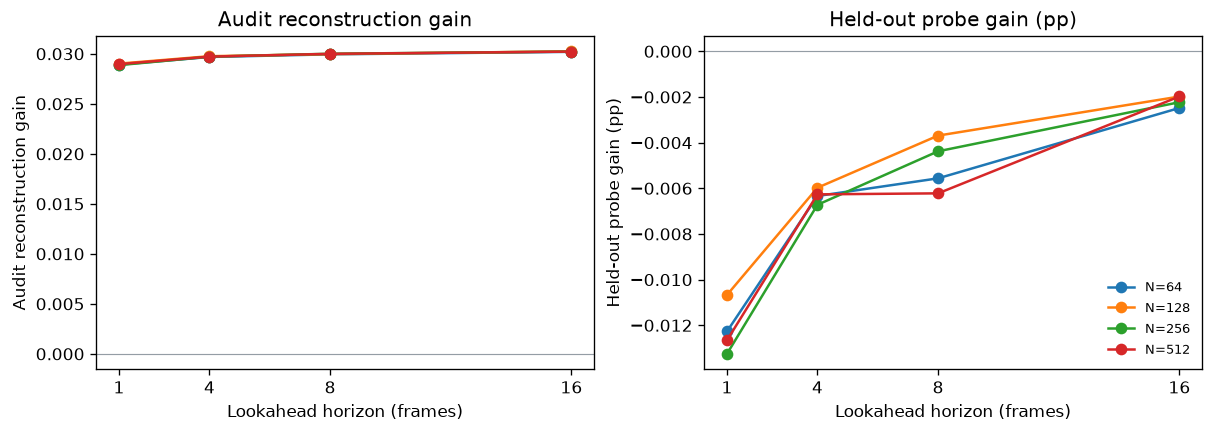

In [ ]:
# Embedded plot from the completed decision states.

### Realized contributions to the weighted score

At 16 frames and 128 bank images, signed contributions add to the selected action’s mean score. Magnitude shares take absolute values per decision before aggregation.

| Rank coefficient | Loss term | Rank term | Net gain | Loss share of magnitude | Rank share of magnitude |
|---:|---:|---:|---:|---:|---:|
| 0% | +1.4057 | +0.0000 | +1.4057 | 100.0% | 0.0% |
| 25% | +1.0440 | -0.0979 | +0.9461 | 91.1% | 8.9% |
| 50% | +0.6467 | -0.1174 | +0.5293 | 83.7% | 16.3% |
| 75% | +0.2556 | -0.0622 | +0.1933 | 77.0% | 23.0% |
| 100% | +0.0000 | +0.0107 | +0.0107 | 0.0% | 100.0% |

## Calibration scales

| Seed | Loss RMS at H = 1 / 4 / 8 / 16 | Rank RMS at N = 64 / 128 / 256 / 512 |
|---|---|---|
| 2026 | 0.033698 / 0.031005 / 0.030212 / 0.028298 | 0.68344 / 0.7498 / 0.79529 / 0.81253 |
| 2027 | 0.044483 / 0.034672 / 0.031945 / 0.029705 | 0.88017 / 0.94803 / 0.98155 / 1.0096 |
| 2028 | 0.028013 / 0.023497 / 0.021697 / 0.02141 | 0.58624 / 0.63578 / 0.6612 / 0.66528 |

## Inspect an individual decision

Edit the file index, horizon and bank size to inspect all six candidates. Choice indices refer to candidates in ascending LR order.

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

rel = Path("analysis/2026-11-09-one-step-mpc/mae-lookahead-a2/results")
out = next(p/rel for p in (Path.cwd(), *Path.cwd().parents) if (p/rel).is_dir())
cases = sorted((out/"cases").glob("*.json"))
if cases:
    index, horizon, size = 0, 16, 128
    row = json.loads(cases[index].read_text())
    spec = json.loads((out/"design.json").read_text())
    h,b = spec["horizons"].index(horizon), spec["sizes"].index(size)
    l = np.array(row["future"])[:,:horizon].mean(1)
    r = np.array(row["rank"])[:,b]
    df = pd.DataFrame(dict(rate=spec["rates"], future_loss=l, loss_gain=l[0]-l,
                           bank_rank=r, rank_gain=r-r[0], frontier=row["frontier"][h][b],
                           audit_rank=np.array(row["audit_rank"])[:,b],
                           probe_Q=[a["q"] for a in row["quality"]]))
    for name,action in zip(spec["policies"],row["choices"][h][b]):
        df[name] = df.index == action
    display(df)
else:
    print("Awaiting the first completed decision.")